In [1]:
import numpy as np
import pandas as pd
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Embedding, GRU, Concatenate, Dense, Bidirectional, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Bidirectional, Concatenate, Activation
from tensorflow.keras.utils import to_categorical
import numpy as np
import numpy as np
import pandas as pd
from tensorflow.keras.utils import to_categorical
import numpy as np
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Concatenate, Activation, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical, plot_model
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Concatenate, Activation, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import numpy as np
import pandas as pd
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Concatenate, Activation, Bidirectional
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import numpy as np
# Load Data
path_X_train = r'/content/X_train_N1UvY30 (1).csv'
path_Y_train = r'/content/y_train_or6m3Ta (1).csv'
path_X_test = r'/content/X_test_m4HAPAP (1).csv'
path_Y_test = r'/content/y_random_cfm (1).csv'


X_train = pd.read_csv(path_X_train)
Y_train = pd.read_csv(path_Y_train)
X_test = pd.read_csv(path_X_test)
Y_test = pd.read_csv(path_Y_test)
print(X_test.columns)
print(X_train.columns)
print("Number of columns in X_test:", len(X_test.columns))
print("Number of columns in X_train:", len(X_test.columns))
print(X_train.head())
print("Number of rows:", len(X_train))


<ipython-input-1-a9ff8c231cbb>:34: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  X_train = pd.read_csv(path_X_train)
<ipython-input-1-a9ff8c231cbb>:36: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  X_test = pd.read_csv(path_X_test)


Index(['obs_id', 'venue', 'order_id', 'action', 'side', 'price', 'bid', 'ask',
       'bid_size', 'ask_size', 'trade', 'flux'],
      dtype='object')
Index(['obs_id', 'venue', 'order_id', 'action', 'side', 'price', 'bid', 'ask',
       'bid_size', 'ask_size', 'trade', 'flux'],
      dtype='object')
Number of columns in X_test: 12
Number of columns in X_train: 12
   obs_id  venue  order_id action side  price  bid   ask  bid_size  ask_size  \
0       0      4         0      A    A   0.30  0.0  0.01     100.0       1.0   
1       0      4         1      A    B  -0.17  0.0  0.01     100.0       1.0   
2       0      4         2      D    A   0.28  0.0  0.01     100.0       1.0   
3       0      4         3      A    A   0.30  0.0  0.01     100.0       1.0   
4       0      4         4      D    A   0.37  0.0  0.01     100.0       1.0   

   trade   flux  
0  False  100.0  
1  False  100.0  
2  False -100.0  
3  False  100.0  
4  False -100.0  
Number of rows: 6394799


In [2]:
#  mapping and encoding
X_train['side'] = X_train['side'].map({'A': 0, 'B': 1}).astype(int)
X_test['side'] = X_test['side'].map({'A': 0, 'B': 1}).astype(int)

action_mapping = {'A': 1, 'D': 0, 'U': 2}
X_train['action'] = X_train['action'].map(action_mapping)
X_test['action'] = X_test['action'].map(action_mapping)


X_train['trade'] = X_train['trade'].fillna(False).astype(int)
X_test['trade'] = X_test['trade'].fillna(False).astype(int)

numeric_features = ['price', 'bid', 'ask', 'bid_size', 'ask_size', 'flux']

# Convert to numeric
for feature in numeric_features:
    X_train[feature] = pd.to_numeric(X_train[feature], errors='coerce').fillna(X_train[feature].median())
    X_test[feature] = pd.to_numeric(X_test[feature], errors='coerce').fillna(X_test[feature].median())
    X_train[feature] = np.log1p(X_train[feature].clip(lower=1))
    X_test[feature] = np.log1p(X_test[feature].clip(lower=1))


X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

# Prepare sequences
sequences = []
labels = []

for obs_id, group in X_train.groupby('obs_id'):
    group = group.sort_values(by='order_id')

    sequence = group[['venue', 'action', 'trade', 'side'] + numeric_features].values
    sequences.append(sequence)
    label = Y_train[Y_train['obs_id'] == obs_id]['eqt_code_cat'].iloc[0]
    labels.append(label)


sequences_padded = pad_sequences(sequences, maxlen=100, dtype='float32', padding='post', truncating='post')
labels_encoded = to_categorical(np.array(labels), num_classes=24)


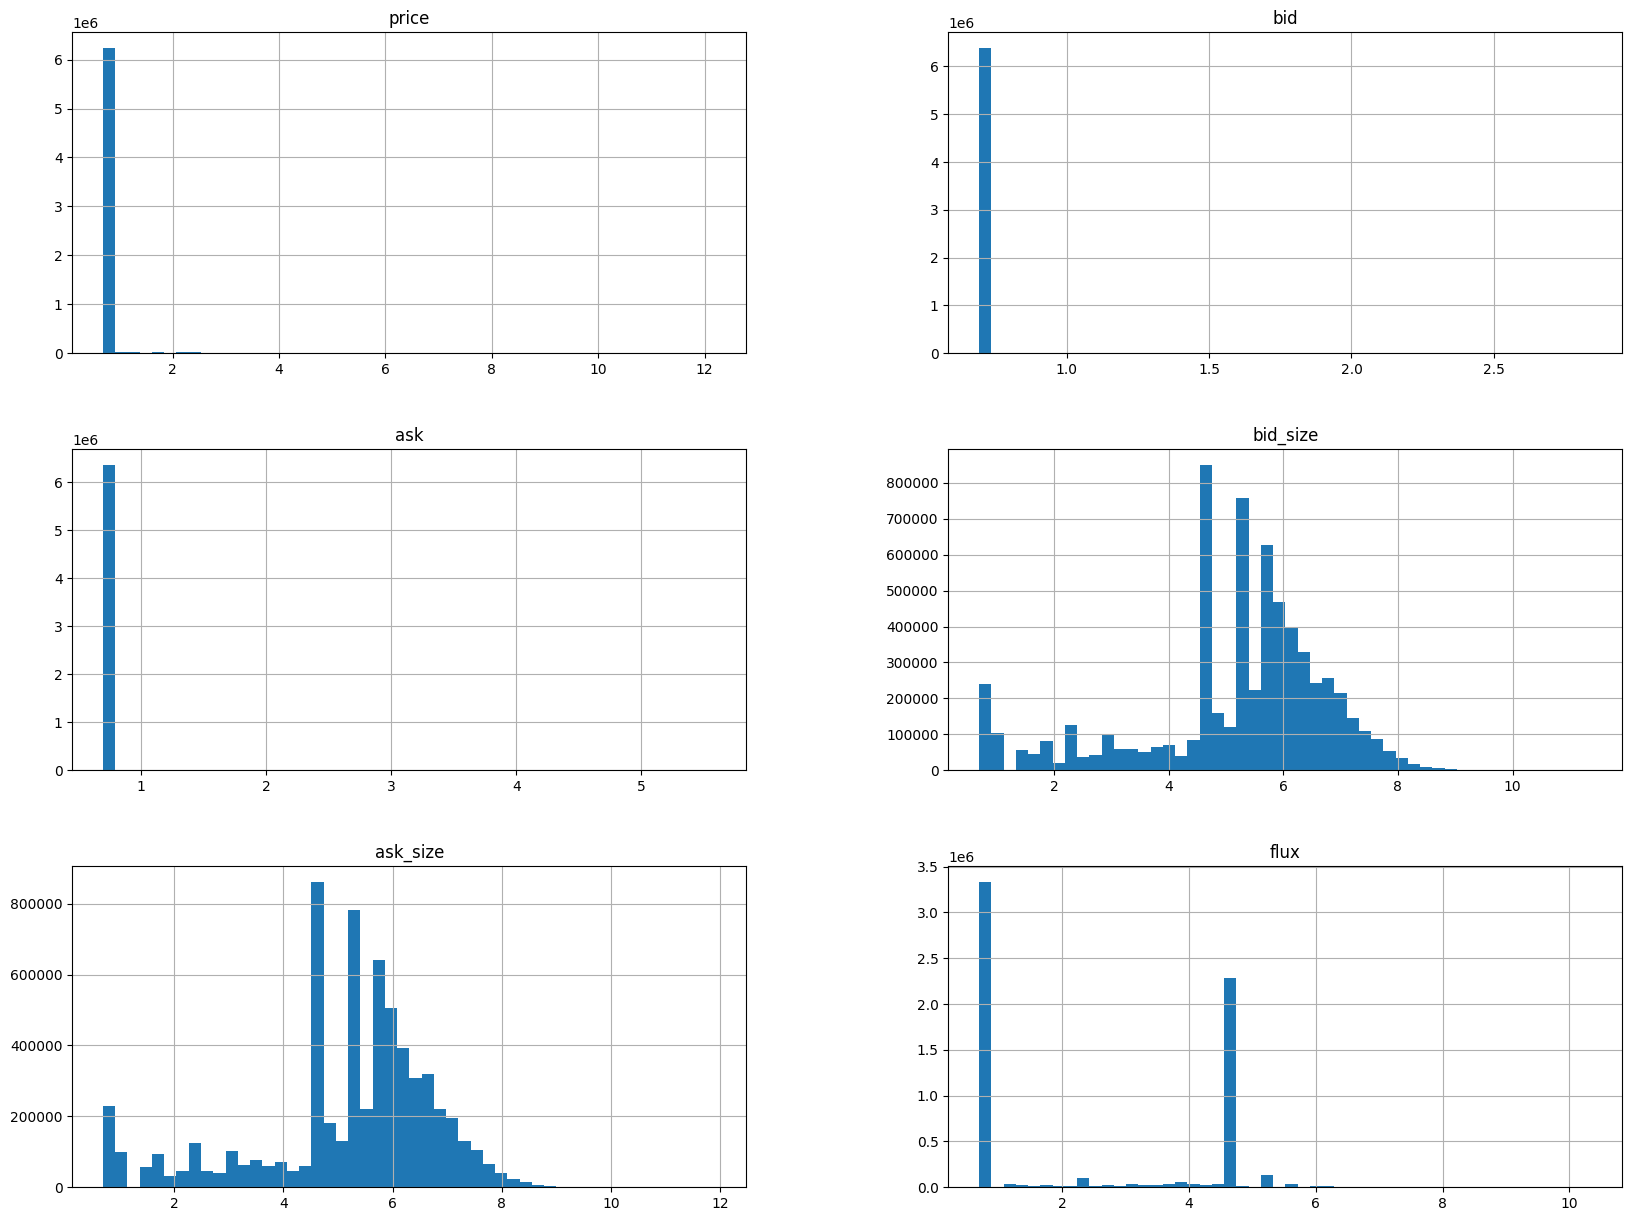

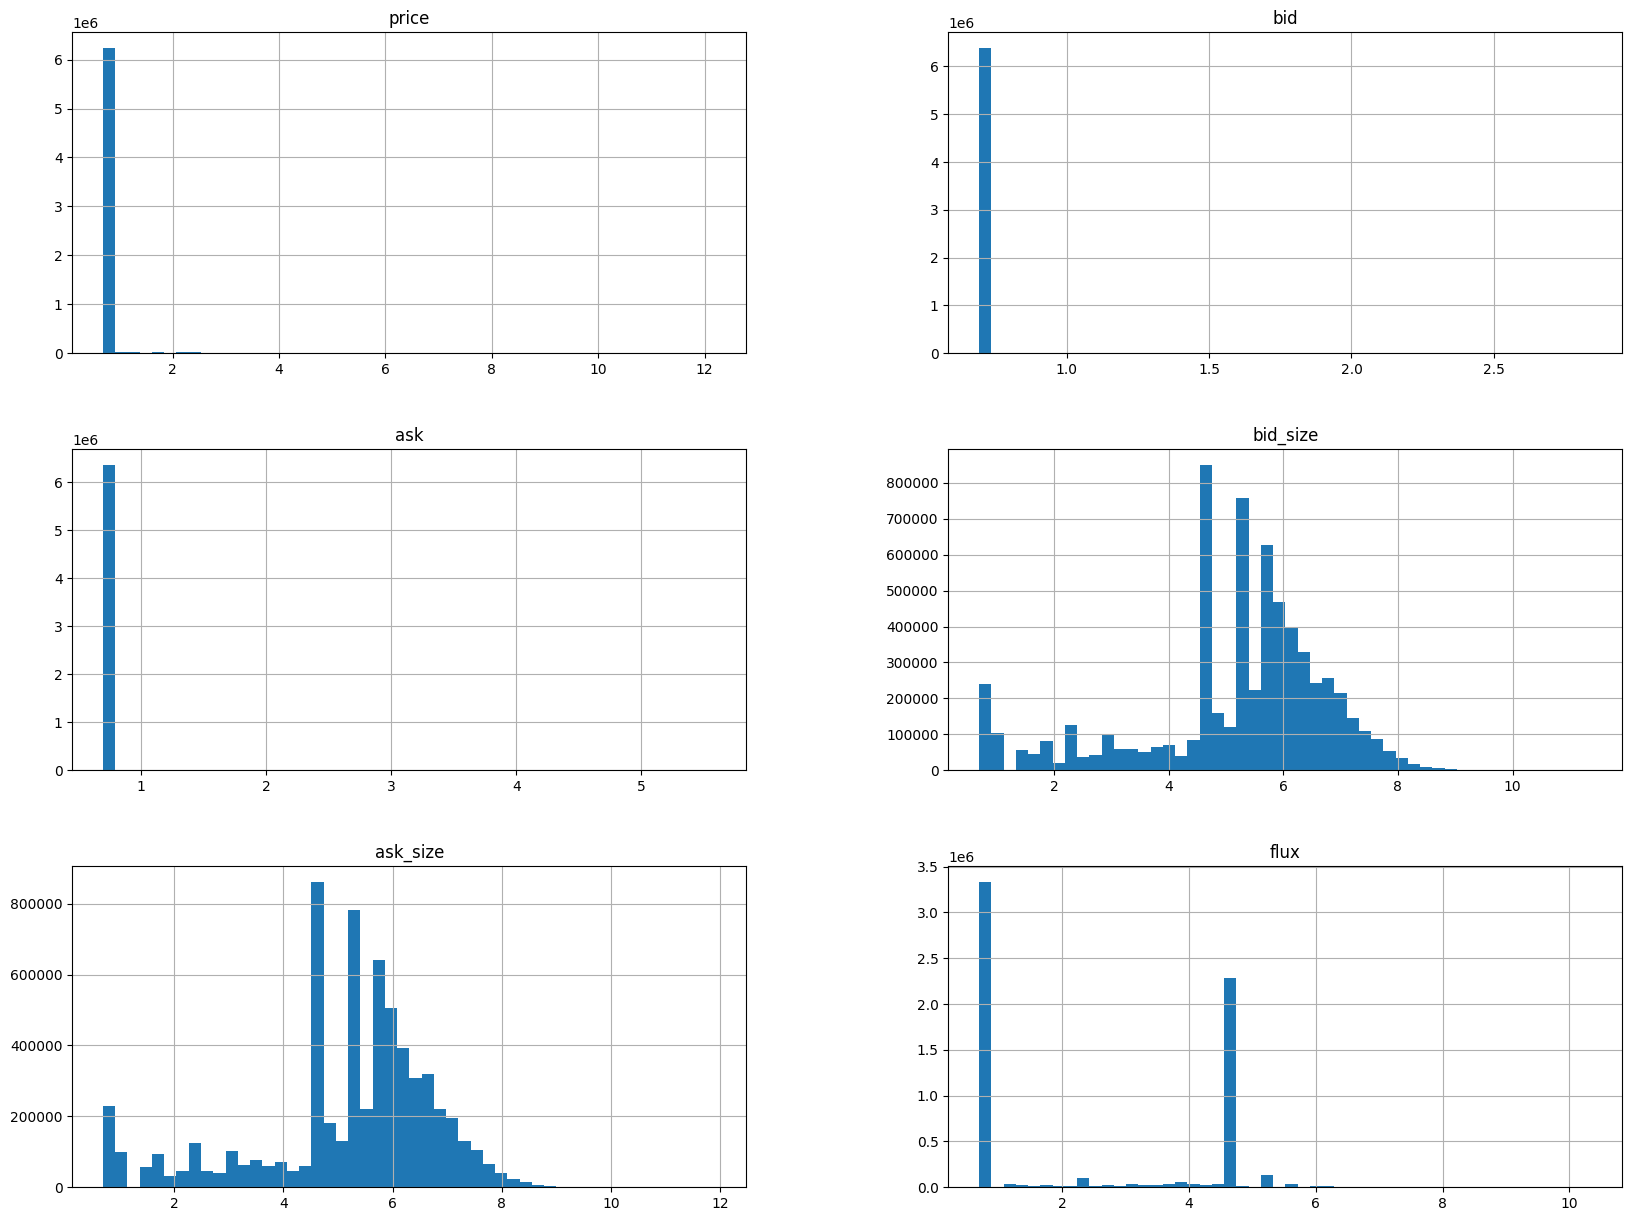

X_train Descriptive Statistics:
              price           bid           ask      bid_size      ask_size  \
count  6.394799e+06  6.394799e+06  6.394799e+06  6.394799e+06  6.394799e+06   
mean   7.371861e-01  6.931603e-01  7.135557e-01  5.153238e+00  5.150834e+00   
std    3.457316e-01  5.309570e-03  2.870030e-01  1.682614e+00  1.674344e+00   
min    6.931472e-01  6.931472e-01  6.931472e-01  6.931472e-01  6.931472e-01   
25%    6.931472e-01  6.931472e-01  6.931472e-01  4.615121e+00  4.615121e+00   
50%    6.931472e-01  6.931472e-01  6.931472e-01  5.416100e+00  5.407172e+00   
75%    6.931472e-01  6.931472e-01  6.931472e-01  6.218600e+00  6.216606e+00   
max    1.220591e+01  2.843164e+00  5.594488e+00  1.138127e+01  1.191916e+01   

               flux  
count  6.394799e+06  
mean   2.454881e+00  
std    1.931883e+00  
min    6.931472e-01  
25%    6.931472e-01  
50%    6.931472e-01  
75%    4.615121e+00  
max    1.035141e+01  

Y_train Descriptive Statistics:
             obs_id   eqt

In [3]:



%matplotlib inline
X_train[numeric_features ].hist(bins=50, figsize=(20,15))
plt.show()
X_train[numeric_features ].hist(bins=50, figsize=(20,15))
plt.show()

print("X_train Descriptive Statistics:")
print(X_train[numeric_features ].describe())


print("\nY_train Descriptive Statistics:")
print(Y_train.describe())



In [ ]:


# Define the maximum values
max_venue = int(np.max([seq[:, 0] for seq in sequences_padded])) + 1

max_action = X_train['action'].max() + 1
max_trade = 2

# Prepare inputs
X_train_seq, X_val_seq, Y_train_enc, Y_val_enc = train_test_split(sequences_padded, labels_encoded, test_size=0.2, random_state=42)

# Splitting sequences into separate inputs
X_train_venue = np.array([seq[:, 0] for seq in X_train_seq]).astype('int32')
X_train_action = np.array([seq[:, 1] for seq in X_train_seq]).astype('int32')
X_train_trade = np.array([seq[:, 2] for seq in X_train_seq]).astype('int32')
X_train_numerical = np.array([seq[:, 4:] for seq in X_train_seq])

X_val_venue = np.array([seq[:, 0] for seq in X_val_seq]).astype('int32')
X_val_action = np.array([seq[:, 1] for seq in X_val_seq]).astype('int32')
X_val_trade = np.array([seq[:, 2] for seq in X_val_seq]).astype('int32')
X_val_numerical = np.array([seq[:, 4:] for seq in X_val_seq])


# Input layers
input_venue = Input(shape=(100,), name='venue_input')
input_action = Input(shape=(100,), name='action_input')
input_trade = Input(shape=(100,), name='trade_input')
numerical_input = Input(shape=(100, 6), name='numerical_input')
# Embeddings
embedding_venue = Embedding(input_dim=max_venue, output_dim=8, input_length=100)(input_venue)
embedding_action = Embedding(input_dim=max_action, output_dim=8, input_length=100)(input_action)
embedding_trade = Embedding(input_dim=max_trade, output_dim=8, input_length=100)(input_trade)

# Concatenate
all_features = Concatenate()([embedding_venue, embedding_action, embedding_trade, numerical_input])

# GRU layers
gru_layer = Bidirectional(GRU(64, return_sequences=True))(all_features)
gru_layer = Bidirectional(GRU(64, return_sequences=False))(gru_layer)

# Dense layers
dense_layer = Dense(64, activation='selu')(gru_layer)

# Final output layer
output_layer = Dense(24, activation='softmax')(dense_layer)

# model
model = Model(inputs=[input_venue, input_action, input_trade, numerical_input], outputs=output_layer)
model.compile(optimizer=Adam(learning_rate=3e-3), loss='categorical_crossentropy', metrics=['accuracy'])




model.summary()


# Train
model.fit([X_train_venue, X_train_action, X_train_trade, X_train_numerical], Y_train_enc, epochs=10, validation_split=0.2, batch_size=1000)


model.save('final_model.h5')
